---
# 实验4. 趋势分析

**目标：**
- 掌握利用Mann-Kendall（MK）方法进行趋势检验。

**数据：**
- 三江源国家公园矢量边界数据（exercises/data/SanJiangYuan/map/boua.shp）；
- 2001-2020年三江源地区 NPP、气温和降水数据（exercises/data/SanJiangYuan）。其中，气温是每年4-10月间的月均温（℃），降水是每年4-10月间的总降水量（mm）。

**实验要求：**
- 利用MK方法分别分析研究区NPP、气温和降水在2001-2020年间的变化趋势。
- 要求分别输出并绘制$p$值、slope和变化趋势（trend）三幅图，并做对比分析。
- 针对上述$p$值、slope和变化趋势（trend）数据，分别分析：
    - 统计显著/不显著像元的占比；
    - 对slope做分级（自行决定分级标准，3-4级为宜），分别统计各级的占比情况（%）；
    - 统计上升/下降趋势的像元占比情况。


In [4]:
pip install numpy pandas matplotlib xarray rasterio pymannkendall

Note: you may need to restart the kernel to use updated packages.


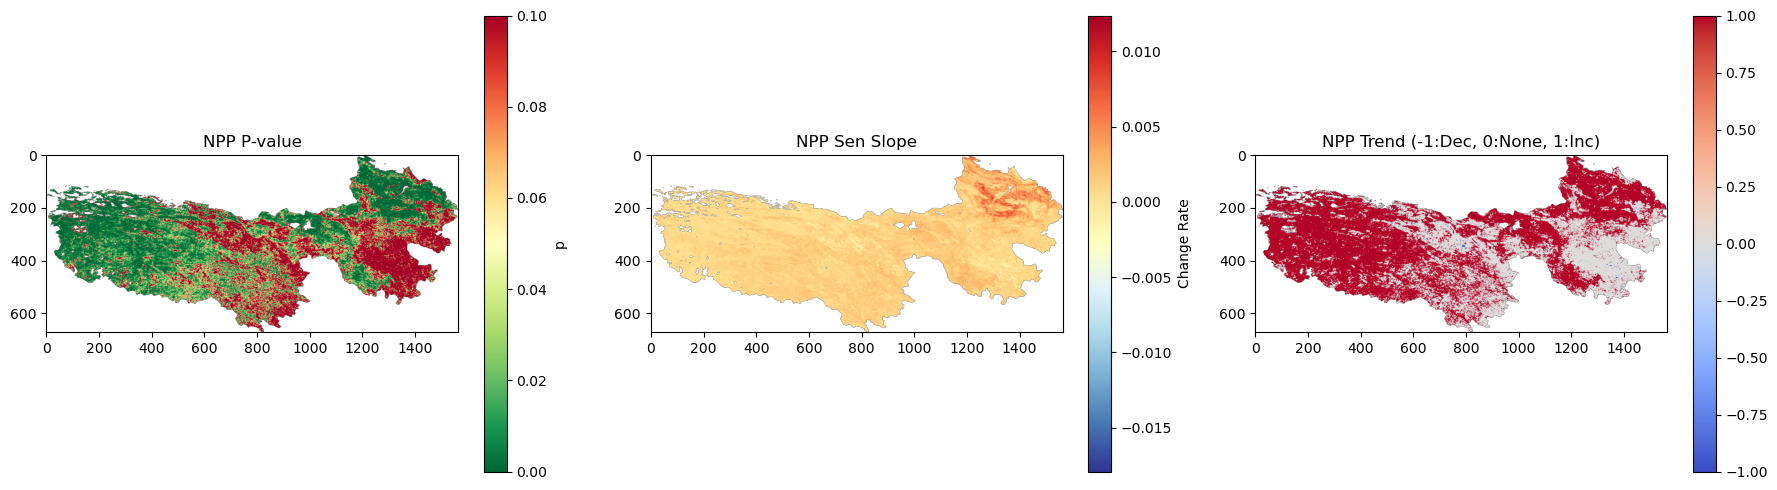

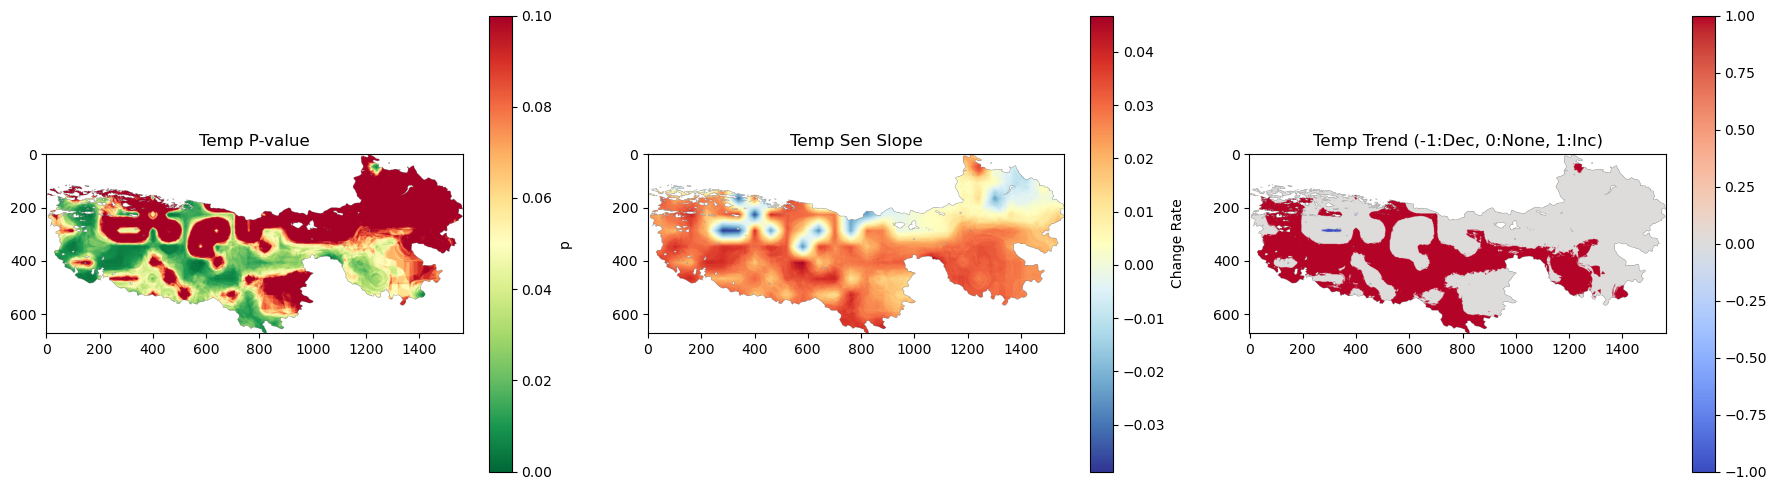

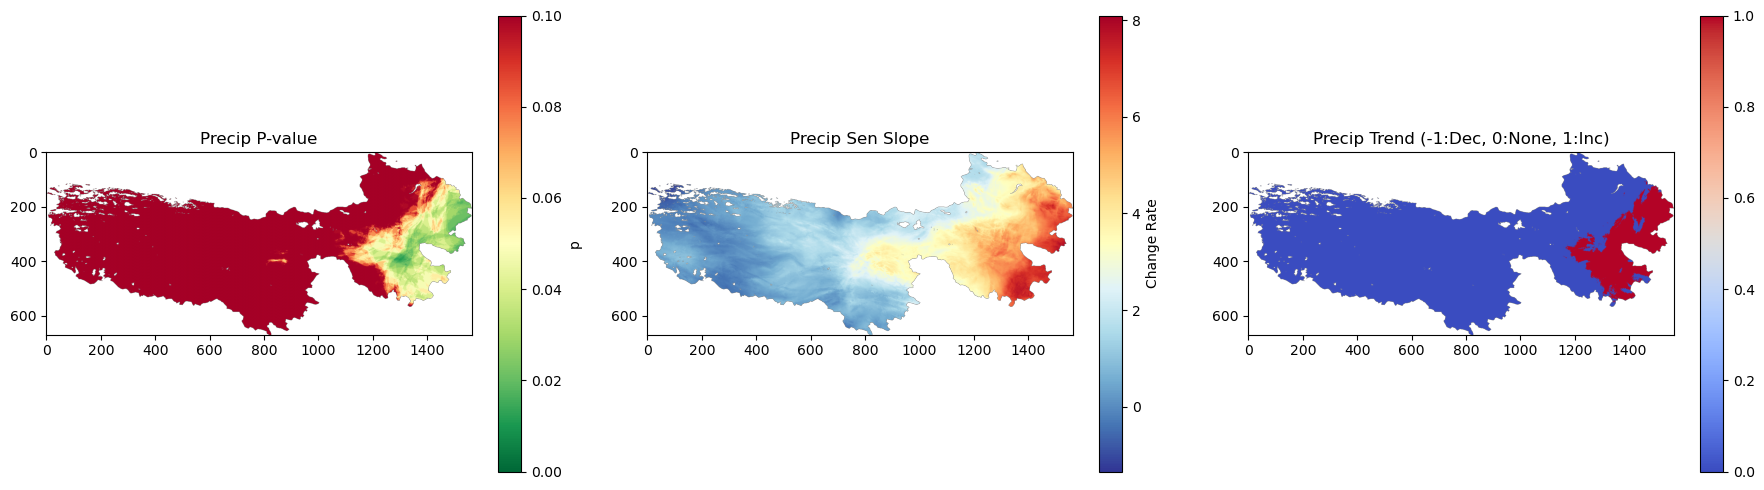

In [13]:
import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import pymannkendall as mk
from glob import glob

# ----------------- 1. 参数设置与数据读取函数 -----------------
base_path = "./data/SanJiangYuan"
years = range(2001, 2021)

def read_tiff_series(folder, prefix):
    """读取时间序列影像并转为3D numpy数组 (time, height, width)"""
    data_list = []
    meta = None
    for year in years:
        file_path = os.path.join(folder, f"{prefix}_{year}.tif")
        with rasterio.open(file_path) as src:
            data_list.append(src.read(1))
            if meta is None:
                meta = src.meta
    return np.array(data_list), meta

# 读取三类数据
npp_data, npp_meta = read_tiff_series(f"{base_path}/NPP", "NPP")
tmp_data, tmp_meta = read_tiff_series(f"{base_path}/Temperature", "tmp")
pre_data, pre_meta = read_tiff_series(f"{base_path}/Precipitation", "pre")

# ----------------- 2. MK 趋势检验计算函数 -----------------
def calculate_mk(data_3d):
    """对每个像元进行MK检验和Sen's Slope计算"""
    t, h, w = data_3d.shape
    p_map = np.full((h, w), np.nan)
    slope_map = np.full((h, w), np.nan)
    trend_map = np.full((h, w), np.nan) # 1:增加, -1:减少, 0:无显著趋势

    for i in range(h):
        for j in range(w):
            pixel_series = data_3d[:, i, j]
            # 排除无效值 (假设tif中NoData为nan或特定负值)
            if not np.isnan(pixel_series).any() and np.std(pixel_series) > 0:
                res = mk.original_test(pixel_series)
                p_map[i, j] = res.p
                slope_map[i, j] = res.slope
                # 显著性水平设为 0.05
                if res.p < 0.05:
                    trend_map[i, j] = 1 if res.slope > 0 else -1
                else:
                    trend_map[i, j] = 0
    return p_map, slope_map, trend_map

# ----------------- 3. 绘图与对比分析 -----------------
def plot_results(p, slope, trend, title_prefix):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # P值图
    im1 = axes[0].imshow(p, cmap='RdYlGn_r', vmin=0, vmax=0.1)
    axes[0].set_title(f'{title_prefix} P-value')
    plt.colorbar(im1, ax=axes[0], label='p')

    # Slope图 (Sen's Slope)
    im2 = axes[1].imshow(slope, cmap='RdYlBu_r')
    axes[1].set_title(f'{title_prefix} Sen Slope')
    plt.colorbar(im2, ax=axes[1], label='Change Rate')

    # Trend图 (显著性分类)
    im3 = axes[2].imshow(trend, cmap='coolwarm')
    axes[2].set_title(f'{title_prefix} Trend (-1:Dec, 0:None, 1:Inc)')
    plt.colorbar(im3, ax=axes[2])
    
    plt.tight_layout()
    plt.show()

# 执行计算与绘图
for name, data in zip(["NPP", "Temp", "Precip"], [npp_data, tmp_data, pre_data]):
    p, s, t = calculate_mk(data)
    plot_results(p, s, t, name)

#### 从结果可以看出，三江源地区2001-2020年气温整体呈显著上升趋势，升温最明显的区域集中在东部和东南部，西北部升温相对缓慢，部分地区存在弱降温趋势。

In [ ]:
import os
import numpy as np
import rasterio
import pymannkendall as mk
from tqdm import tqdm

# ----------------- 1. 参数与路径设置 -----------------
input_base = "./data/SanJiangYuan"
output_dir = "./outputs"
years = range(2001, 2021)

if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# ----------------- 2. 定义数据读取函数 -----------------
def read_tiff_series(folder, prefix):
    """读取时间序列影像并转为3D numpy数组"""
    data_list = []
    meta = None
    print(f"正在读取 {prefix} 数据...")
    for year in years:
        file_path = os.path.join(folder, f"{prefix}_{year}.tif")
        with rasterio.open(file_path) as src:
            data_list.append(src.read(1))
            if meta is None:
                meta = src.meta.copy()
    return np.array(data_list), meta

# ----------------- 3. 定义计算与保存函数 -----------------
def process_and_save(data_3d, meta, var_name):
    """计算 MK 结果并保存为 GeoTIFF"""
    t, h, w = data_3d.shape
    p_map = np.full((h, w), np.nan, dtype=np.float32)
    slope_map = np.full((h, w), np.nan, dtype=np.float32)
    trend_map = np.full((h, w), np.nan, dtype=np.float32)

    print(f"正在计算 {var_name} 的 MK 趋势...")
    for i in tqdm(range(h)):
        for j in range(w):
            pixel_series = data_3d[:, i, j]
            # 过滤无效值（NoData通常为nan或极小值，且序列不能全是重复值）
            if not np.isnan(pixel_series).any() and np.std(pixel_series) > 1e-6:
                try:
                    res = mk.original_test(pixel_series)
                    p_map[i, j] = res.p
                    slope_map[i, j] = res.slope
                    # 趋势：1显著上升, -1显著下降, 0不显著
                    if res.p < 0.05:
                        trend_map[i, j] = 1 if res.slope > 0 else -1
                    else:
                        trend_map[i, j] = 0
                except:
                    continue

    # 更新元数据
    meta.update(dtype=rasterio.float32, count=1, nodata=np.nan)

    # 保存到指定目录
    res_dict = {'p_value': p_map, 'slope': slope_map, 'trend': trend_map}
    for key, arr in res_dict.items():
        out_path = os.path.join(output_dir, f"{var_name}_{key}.tif")
        with rasterio.open(out_path, 'w', **meta) as dst:
            dst.write(arr, 1)
    
    return p_map, slope_map, trend_map

# ----------------- 4. 定义快速统计函数 -----------------
def quick_stats(p, slope, trend, var_name, slope_bins):
    mask = ~np.isnan(slope)
    v_p, v_s, v_t = p[mask], slope[mask], trend[mask]
    total = v_s.size
    
    if total == 0: return

    print(f"\n===== {var_name} 统计报告 =====")
    print(f"1. 显著性: 显著(p<0.05)占 {np.sum(v_p<0.05)/total:.2%}, 不显著占 {np.sum(v_p>=0.05)/total:.2%}")
    
    low, high = slope_bins
    r1 = np.sum(v_s < low) / total
    r2 = np.sum((v_s >= low) & (v_s <= high)) / total
    r3 = np.sum(v_s > high) / total
    print(f"2. Slope分级: 下降(<{low}): {r1:.2%}, 稳定({low}~{high}): {r2:.2%}, 上升(>{high}): {r3:.2%}")
    
    print(f"3. 趋势判定: 显著上升 {np.sum(v_t==1)/total:.2%}, 显著下降 {np.sum(v_t==-1)/total:.2%}, 无显著变化 {np.sum(v_t==0)/total:.2%}")

# ----------------- 5. 主程序执行流程 -----------------
if __name__ == "__main__":
    # --- A. NPP 处理 ---
    npp_data, npp_meta = read_tiff_series(f"{input_base}/NPP", "NPP")
    pn, sn, tn = process_and_save(npp_data, npp_meta, "NPP")
    quick_stats(pn, sn, tn, "NPP", [-5, 5])

    # --- B. 气温 处理 ---
    tmp_data, tmp_meta = read_tiff_series(f"{input_base}/Temperature", "tmp")
    pt, st, tt = process_and_save(tmp_data, tmp_meta, "Temp")
    quick_stats(pt, st, tt, "Temp", [0, 0.02])

    # --- C. 降水 处理 ---
    pre_data, pre_meta = read_tiff_series(f"{input_base}/Precipitation", "pre")
    pp, sp, tp = process_and_save(pre_data, pre_meta, "Precip")
    quick_stats(pp, sp, tp, "Precip", [-2, 2])

正在读取 NPP 数据...
正在计算 NPP 的 MK 趋势...


100%|██████████| 671/671 [13:16<00:00,  1.19s/it]



===== NPP 统计报告 =====
1. 显著性: 显著(p<0.05)占 62.15%, 不显著占 37.85%
2. Slope分级: 下降(<-5): 0.00%, 稳定(-5~5): 100.00%, 上升(>5): 0.00%
3. 趋势判定: 显著上升 61.87%, 显著下降 0.28%, 无显著变化 37.85%
正在读取 tmp 数据...
正在计算 Temp 的 MK 趋势...


100%|██████████| 671/671 [23:15<00:00,  2.08s/it]



===== Temp 统计报告 =====
1. 显著性: 显著(p<0.05)占 38.59%, 不显著占 61.41%
2. Slope分级: 下降(<0): 10.78%, 稳定(0~0.02): 27.38%, 上升(>0.02): 61.84%
3. 趋势判定: 显著上升 38.45%, 显著下降 0.14%, 无显著变化 61.41%
正在读取 pre 数据...
正在计算 Precip 的 MK 趋势...


100%|██████████| 671/671 [21:22<00:00,  1.91s/it]


===== Precip 统计报告 =====
1. 显著性: 显著(p<0.05)占 11.99%, 不显著占 88.01%
2. Slope分级: 下降(<-2): 0.00%, 稳定(-2~2): 56.65%, 上升(>2): 43.35%
3. 趋势判定: 显著上升 11.99%, 显著下降 0.00%, 无显著变化 88.01%
